# Task 6 — Web Scraping and Analysis of Job Postings

**Goal:** collect public job ads from a real website, check its `robots.txt`, extract job title, company, location, date and skills, clean the data, and analyze job demand.

## Source and collection scope

This notebook uses the public HTML listings page at [We Work Remotely](https://weworkremotely.com/remote-jobs). Its `robots.txt` allows public pages; the site also says its public jobs feed may be used with attribution. This project reads the **HTML page**, not an API. We keep the source link for each ad and link back to the site, as requested in its [terms](https://weworkremotely.com/terms-and-conditions).

The collection is intentionally small and polite: one listing page, then up to 15 linked detail pages, requested one at a time with a one-second pause. This is a snapshot of **remote jobs shown on the source page**; it does not represent every occupation or the entire job market. Since the cards show relative posting ages, the notebook converts them to approximate dates using the scrape date.

## 1. Imports and request settings

Import only the tools used in this analysis. The user agent identifies this as a student project; requests are sequential and limited.

In [1]:
import re
import time
from datetime import date, timedelta
from urllib.parse import urljoin, urlparse
from urllib.robotparser import RobotFileParser

import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from IPython.display import display

page_url = "https://weworkremotely.com/remote-jobs"
site_root = "https://weworkremotely.com"
user_agent = "Mozilla/5.0 (compatible; ElevvoTask6Student/1.0)"
headers = {"User-Agent": user_agent}
scraped_on = date.today()
print("Listing page:", page_url)
print("Snapshot date:", scraped_on.isoformat())

Listing page: https://weworkremotely.com/remote-jobs
Snapshot date: 2026-10-27


## 2. Check `robots.txt` before fetching job listings

Read the site's robot rules and ask Python whether the listing page is allowed for this user agent. Stop if it is disallowed. The same check will be repeated before each detail page.

In [2]:
robots_url = urljoin(site_root, "/robots.txt")
robots_response = requests.get(robots_url, headers=headers, timeout=30)
print("robots.txt status:", robots_response.status_code)
robots_response.raise_for_status()

robots = RobotFileParser()
robots.set_url(robots_url)
robots.parse(robots_response.text.splitlines())
listing_allowed = robots.can_fetch(user_agent, page_url)
print("Listing page allowed:", listing_allowed)

if not listing_allowed:
    raise PermissionError("The site's robots.txt does not allow this listing page.")

robots.txt status: 200
Listing page allowed: True


## 3. Fetch the public HTML listing page

Make one request to the allowed page, then use BeautifulSoup to read the job cards. Sponsored cards are excluded so the analysis covers job postings, not ads.

In [3]:
time.sleep(1)
page_response = requests.get(page_url, headers=headers, timeout=30)
page_response.raise_for_status()
print("Page status:", page_response.status_code)
print("HTML size:", len(page_response.content), "bytes")

soup = BeautifulSoup(page_response.text, "html.parser")
cards = soup.select("li.feature")
jobs = []

for card in cards:
    link = card.select_one("a.listing-link--unlocked")
    title = card.select_one(".new-listing__header__title__text")
    company = card.select_one(".new-listing__company-name")
    date_label = card.select_one(".new-listing__header__icons__date")
    headquarters = card.select_one(".new-listing__company-headquarters")
    categories = [x.get_text(" ", strip=True) for x in card.select(".new-listing__categories__category")]

    if not all([link, title, company]):
        continue

    jobs.append({
        "job_title": title.get_text(" ", strip=True),
        "company": company.get_text(" ", strip=True),
        "company_headquarters": headquarters.get_text(" ", strip=True).replace("HQ:", "", 1).strip() if headquarters else None,
        "posted_label": date_label.get_text(" ", strip=True) if date_label else None,
        "categories": ", ".join(categories),
        "job_url": urljoin(page_url, link.get("href", "")),
        "source": "We Work Remotely",
        "scraped_on": scraped_on.isoformat(),
    })

raw_jobs = pd.DataFrame(jobs).drop_duplicates(subset="job_url").reset_index(drop=True)
print("Job cards collected:", len(raw_jobs))
display(raw_jobs.head(8))

Page status: 200
HTML size: 421455 bytes


Job cards collected: 64


,job_title,company,company_headquarters,posted_label,categories,job_url,source,scraped_on
0,Principal Solutions Consultant,PagerDuty,Remote (USA),21d,"Full-Time, Anywhere in the World",https://weworkremotely.com/remote-jobs/pagerdu...,We Work Remotely,2026-10-27
1,Head of Communications,Tailscale,Canada,New,"Boosted, Featured, Full-Time, $100,000 or more...",https://weworkremotely.com/remote-jobs/tailsca...,We Work Remotely,2026-10-27
2,(Developmental) Content Editor,Animalz,"New York, NY",4d,"Featured, Top 100, Contract, Anywhere in the W...",https://weworkremotely.com/remote-jobs/animalz...,We Work Remotely,2026-10-27
3,Head of Content and Editorial,OnTheGoSystems,Remote,4d,"Featured, Top 100, Full-Time, $75,000 - $99,99...",https://weworkremotely.com/remote-jobs/onthego...,We Work Remotely,2026-10-27
4,Appointment Setter,Vechter Home Solutions,"Charlotte, NC",6d,"Featured, Full-Time, $75,000 - $99,999 USD, 🇺🇸...",https://weworkremotely.com/remote-jobs/vechter...,We Work Remotely,2026-10-27
5,Sr. Motion Designer,Zapier,United States,12d,"Boosted, Featured, Top 100, Full-Time, $100,00...",https://weworkremotely.com/remote-jobs/zapier-...,We Work Remotely,2026-10-27
6,Principal Product Marketing Manager,ClickHouse,United States,12d,"Boosted, Featured, Full-Time, $100,000 or more...",https://weworkremotely.com/remote-jobs/clickho...,We Work Remotely,2026-10-27
7,Inside Sales - Account Executive,Credit Wellness LLC,USA,17d,"Featured, Contract, $75,000 - $99,999 USD, Any...",https://weworkremotely.com/remote-jobs/credit-...,We Work Remotely,2026-10-27


## 4. Collect a small sample of job descriptions

The listing cards do not contain full descriptions, so fetch up to 15 job pages to identify skills from their text. Before each request, check `robots.txt` for that exact URL. Requests are sequential with a one-second pause. If a page is disallowed or unavailable, leave its description blank and continue.

In [4]:
def get_job_description(job_url):
    if urlparse(job_url).netloc != urlparse(site_root).netloc:
        return None, "outside source host"
    if not robots.can_fetch(user_agent, job_url):
        return None, "disallowed by robots.txt"

    time.sleep(1)
    response = requests.get(job_url, headers=headers, timeout=30)
    if response.status_code != 200:
        return None, f"HTTP {response.status_code}"

    detail_soup = BeautifulSoup(response.text, "html.parser")
    content = detail_soup.select_one(".content")
    if content is None:
        return None, "description area not found"

    # Keep the job text and remove page headings and action buttons.
    for item in content.select("h1, h2, h3, button, form, nav"):
        item.decompose()
    return content.get_text(" ", strip=True), "collected"

raw_jobs["description"] = None
raw_jobs["detail_status"] = "not sampled"
sample_size = min(15, len(raw_jobs))

for index in range(sample_size):
    description, status = get_job_description(raw_jobs.loc[index, "job_url"])
    raw_jobs.loc[index, "description"] = description
    raw_jobs.loc[index, "detail_status"] = status

print("Detail pages sampled:", sample_size)
print("Descriptions collected:", int(raw_jobs["description"].notna().sum()))
display(raw_jobs[["job_title", "company", "detail_status"]].head(sample_size))

Detail pages sampled: 15
Descriptions collected: 15


,job_title,company,detail_status
0,Principal Solutions Consultant,PagerDuty,collected
1,Head of Communications,Tailscale,collected
2,(Developmental) Content Editor,Animalz,collected
3,Head of Content and Editorial,OnTheGoSystems,collected
4,Appointment Setter,Vechter Home Solutions,collected
5,Sr. Motion Designer,Zapier,collected
6,Principal Product Marketing Manager,ClickHouse,collected
7,Inside Sales - Account Executive,Credit Wellness LLC,collected
8,Remote Inside Sales,Your Resource Group LLC,collected
9,Head of Marketing,OnTheGoSystems,collected


## 5. Clean the fields and derive approximate posting dates

Trim whitespace, standardize empty values, and turn relative age labels (for example `3d` or `2w`) into approximate dates. `h` and `m` labels are treated as same-day postings. These dates are estimates based on the collection date, not exact timestamps.

In [5]:
clean_jobs = raw_jobs.copy()

for column in ["job_title", "company", "company_headquarters", "categories", "description"]:
    clean_jobs[column] = clean_jobs[column].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    clean_jobs[column] = clean_jobs[column].replace("", "Not listed")

def age_to_date(label, collected_date):
    if not isinstance(label, str):
        return pd.NaT
    match = re.search(r"(\d+)\s*([mhdw])", label.lower())
    if not match:
        return pd.NaT
    amount = int(match.group(1))
    unit = match.group(2)
    days = {"m": 0, "h": 0, "d": 1, "w": 7}[unit] * amount
    return collected_date - timedelta(days=days)

clean_jobs["posted_date_estimate"] = clean_jobs.apply(
    lambda row: age_to_date(row["posted_label"], date.fromisoformat(row["scraped_on"])), axis=1
)
clean_jobs["employment_type"] = clean_jobs["categories"].str.extract(r"(Full-Time|Part-Time|Contract|Freelance|Temporary|Internship)", expand=False).fillna("Not specified")
def location_scope(categories):
    if "Anywhere in the World" in categories:
        return "Anywhere in the World"
    countries = re.findall(r"[\U0001F1E6-\U0001F1FF]{2}\s*([^,]+)", categories)
    countries = [country.strip() for country in countries]
    if not countries:
        return "Not specified"
    if len(countries) == 1:
        return countries[0]
    return "Multiple countries"

clean_jobs["work_location_scope"] = clean_jobs["categories"].apply(location_scope)
def role_family(title):
    title = title.lower()
    families = [
        (r"data scientist|data analyst|machine learning|artificial intelligence|ai|analytics", "Data & AI"),
        (r"engineer|developer|software|web development|devops|security|qa |quality assurance|sre", "Engineering & IT"),
        (r"sales|account executive|business development|marketing|communications|content", "Sales & Marketing"),
        (r"customer support|customer success|support specialist|appointment setter", "Customer Support"),
        (r"designer|design|creative|editor", "Design & Content"),
        (r"product manager|product marketing|project manager|program manager", "Product & Project"),
        (r"finance|accountant|human resources|recruit|legal|operations", "Business Operations"),
    ]
    for pattern, family in families:
        if re.search(pattern, title):
            return family
    return "Other"

clean_jobs["role_family"] = clean_jobs["job_title"].apply(role_family)
clean_jobs["skill_text"] = clean_jobs["description"].where(clean_jobs["description"] != "Not listed", clean_jobs["job_title"] + " " + clean_jobs["categories"])

print("Rows after deduplication:", len(clean_jobs))
print("Missing job titles:", int((clean_jobs["job_title"] == "Not listed").sum()))
print("Unique job links:", clean_jobs["job_url"].nunique())
display(clean_jobs[["job_title", "company", "company_headquarters", "work_location_scope", "posted_label", "posted_date_estimate", "employment_type"]].head(10))

Rows after deduplication: 64
Missing job titles: 0
Unique job links: 64


,job_title,company,company_headquarters,work_location_scope,posted_label,posted_date_estimate,employment_type
0,Principal Solutions Consultant,PagerDuty,Remote (USA),Anywhere in the World,21d,2026-10-06,Full-Time
1,Head of Communications,Tailscale,Canada,Canada,New,NaT,Full-Time
2,(Developmental) Content Editor,Animalz,"New York, NY",Anywhere in the World,4d,2026-10-23,Contract
3,Head of Content and Editorial,OnTheGoSystems,Remote,Anywhere in the World,4d,2026-10-23,Full-Time
4,Appointment Setter,Vechter Home Solutions,"Charlotte, NC",United States of America,6d,2026-10-21,Full-Time
5,Sr. Motion Designer,Zapier,United States,Anywhere in the World,12d,2026-10-15,Full-Time
6,Principal Product Marketing Manager,ClickHouse,United States,United States of America,12d,2026-10-15,Full-Time
7,Inside Sales - Account Executive,Credit Wellness LLC,USA,Anywhere in the World,17d,2026-10-10,Contract
8,Remote Inside Sales,Your Resource Group LLC,USA,Anywhere in the World,24d,2026-10-03,Contract
9,Head of Marketing,OnTheGoSystems,Remote,Anywhere in the World,28d,2026-09-29,Full-Time


## 6. Analyze roles, locations, and skill mentions

Count job titles and locations directly. Skill frequency is a keyword scan over the descriptions collected from the detail-page sample; if a description was not collected, the title and listing categories are used. This is a simple, transparent keyword method, so it may miss synonyms and skills not in the list.

In [6]:
top_roles = clean_jobs["job_title"].value_counts().head(10)
top_locations = clean_jobs.loc[clean_jobs["work_location_scope"] != "Not specified", "work_location_scope"].value_counts().head(10)
top_role_families = clean_jobs["role_family"].value_counts().head(10)

skill_terms = [
    "python", "sql", "excel", "power bi", "tableau", "machine learning", "data analysis",
    "data science", "aws", "azure", "google cloud", "javascript", "react", "typescript",
    "java", "kubernetes", "docker", "sales", "marketing", "customer support", "project management"
]
skill_counts = {}
for skill in skill_terms:
    count = clean_jobs["skill_text"].str.contains(r"\b" + re.escape(skill) + r"\b", case=False, regex=True).sum()
    if count:
        skill_counts[skill.title()] = int(count)
top_skills = pd.Series(skill_counts, dtype="int64").sort_values(ascending=False).head(10)

print("Most common job titles")
print("Job title counts (titles are mostly distinct, so role families below are more useful for comparison)")
display(top_roles.rename("postings").to_frame().head(5))
print("Role family counts")
display(top_role_families.rename("postings").to_frame())
print("Most common work-location scopes (a broad category when ads list several countries)")
display(top_locations.rename("postings").to_frame())
print("Most mentioned skill keywords (full text sample + card fallback)")
display(top_skills.rename("postings mentioning term").to_frame())

Most common job titles
Job title counts (titles are mostly distinct, so role families below are more useful for comparison)


,postings
job_title,
Principal Solutions Consultant,1
Head of Communications,1
(Developmental) Content Editor,1
Head of Content and Editorial,1
Appointment Setter,1


Role family counts


,postings
role_family,
Engineering & IT,24
Other,15
Sales & Marketing,9
Design & Content,6
Business Operations,4
Customer Support,3
Product & Project,2
Data & AI,1


Most common work-location scopes (a broad category when ads list several countries)


,postings
work_location_scope,
Anywhere in the World,33
United States of America,13
Multiple countries,8
Canada,2
United Kingdom of Great Britain and Northern Ireland,1


Most mentioned skill keywords (full text sample + card fallback)


,postings mentioning term
Marketing,12
Sales,12
Python,3
Javascript,3
React,2
Typescript,1
Sql,1
Java,1
Project Management,1


## 7. Visualize the main findings

The charts summarize listing counts. The skill chart is based on keyword mentions and should be read as a sample, not a full skill taxonomy.

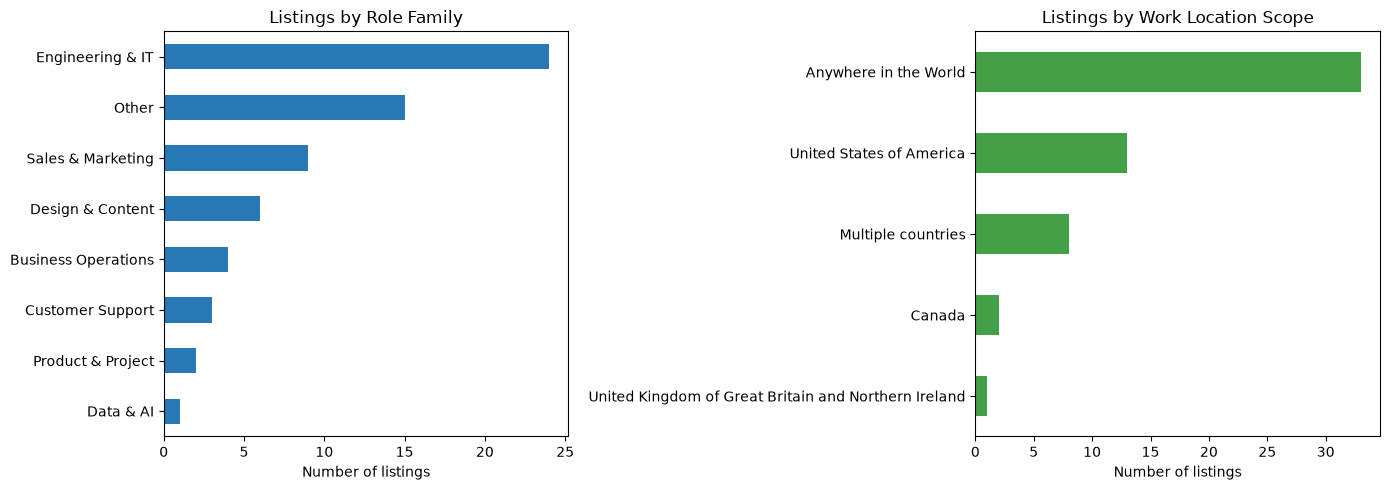

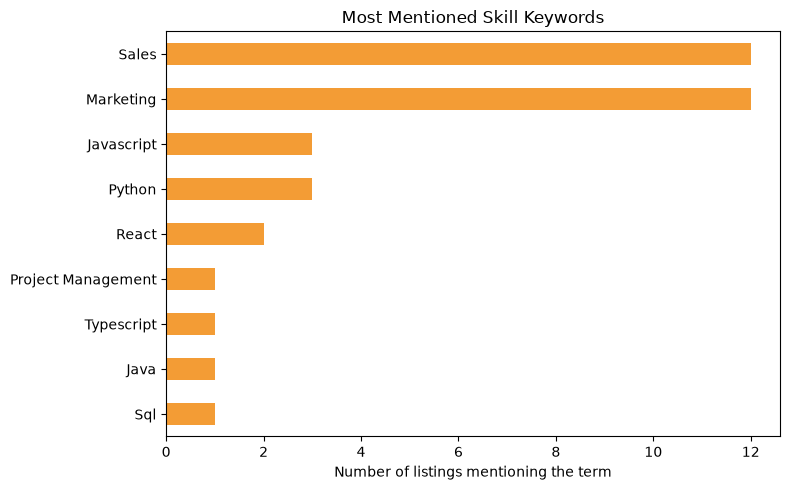

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_role_families.sort_values().plot(kind="barh", ax=axes[0], color="#2878B5")
axes[0].set_title("Listings by Role Family")
axes[0].set_xlabel("Number of listings")
axes[0].set_ylabel("")

top_locations.sort_values().plot(kind="barh", ax=axes[1], color="#43A047")
axes[1].set_title("Listings by Work Location Scope")
axes[1].set_xlabel("Number of listings")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

if not top_skills.empty:
    top_skills.sort_values().plot(kind="barh", figsize=(8, 5), color="#F39C35")
    plt.title("Most Mentioned Skill Keywords")
    plt.xlabel("Number of listings mentioning the term")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

## 8. Summary and limitations

Use the outputs above to identify the leading role, location, and skill keyword in this snapshot. Mention that the sample is remote-work focused, small, and time-sensitive; skills are found with a short keyword list, and some full descriptions are not sampled. Relative posting dates are approximate.

In [8]:
if len(clean_jobs):
    print(f"Collected {len(clean_jobs)} unique job listings from {clean_jobs['source'].iloc[0]}.")
    print("Top role:", top_roles.index[0] if len(top_roles) else "Not available")
    print("Top role family:", top_role_families.index[0] if len(top_role_families) else "Not available")
    print("Top work-location scope:", top_locations.index[0] if len(top_locations) else "Not available")
    print("Top skill keyword:", top_skills.index[0] if len(top_skills) else "Not available")
    print("Listings with collected full descriptions:", int((clean_jobs["description"] != "Not listed").sum()))
    print("The findings describe this page snapshot, not the whole labor market.")
else:
    print("No job listings were collected. Check the page structure or network response.")

Collected 64 unique job listings from We Work Remotely.
Top role: Principal Solutions Consultant
Top role family: Engineering & IT
Top work-location scope: Anywhere in the World
Top skill keyword: Marketing
Listings with collected full descriptions: 15
The findings describe this page snapshot, not the whole labor market.


## 9. Save raw and cleaned data

The raw file preserves the scraped values and collection status. The cleaned file adds normalized fields and estimated dates for analysis. Both files retain each source URL.

In [9]:
raw_path = "job_postings_scraped_raw.csv"
clean_path = "job_postings_cleaned.csv"
raw_jobs.to_csv(raw_path, index=False, encoding="utf-8-sig")
clean_jobs.to_csv(clean_path, index=False, encoding="utf-8-sig")
print("Saved:", raw_path)
print("Saved:", clean_path)

Saved: job_postings_scraped_raw.csv
Saved: job_postings_cleaned.csv
